# Actividad práctico-experimental en el entorno académico

## Detección de outliers
![Logo del ITQ](img/ITQlogo.png)

| Campo | Información |
|---|---|
| **Cargo** | Docente Especialista |
| **Nombre del docente** | Ing. Elvis Pachacama Cabezas |
| **Asignatura** | Fundamentos de Machine Learning |
| **Carrera** | Inteligencia Artificial |
| **Estudiante** | Edgar Enrique Crespo Ch. |
| **Fecha** | 16-11-2026 |
| **Repositorio** |

In [7]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.covariance import EllipticEnvelope
import matplotlib.pyplot as plt

**Explicación línea por línea**

- `import pandas as pd`: importa la librería *pandas* (manejo de tablas) con el alias `pd`.
- `import numpy as np`: importa *NumPy* (arreglos y operaciones numéricas) con el alias `np`.
- `from scipy import stats`: importa el módulo de estadística de *SciPy*; se usará para calcular percentiles (`scoreatpercentile`).
- `from sklearn.covariance import EllipticEnvelope`: importa el detector de outliers que ajusta una elipse (distribución gaussiana) a los datos.
- `import matplotlib.pyplot as plt`: importa *matplotlib* para graficar, con el alias `plt`.

In [8]:
# Carga de datos.
df = pd.read_csv("outliers.csv")
print(df.head())

          a         b
0  0.149014 -0.041479
1  0.194307  0.456909
2 -0.070246 -0.070241
3  0.473764  0.230230
4 -0.140842  0.162768


**Explicación línea por línea**

- `# Carga de datos.`: comentario; no se ejecuta.
- `df = pd.read_csv("outliers.csv")`: lee el archivo CSV y guarda su contenido en un DataFrame llamado `df`.
- `print(df.head())`: muestra las primeras 5 filas para revisar que los datos se cargaron bien.

**0.1.1  1) EllipticEnvelope()**

In [10]:
from sklearn.covariance import EllipticEnvelope

# Usamos las columnas numéricas a y b para entrenar el modelo.
X = df[["a", "b"]]

algorithm = EllipticEnvelope(contamination=0.25, random_state=42)
algorithm.fit(X)

# Agregamos una etiqueta por fila.
df["outlier"] = algorithm.predict(X)

print(df.head())

          a         b  outlier
0  0.149014 -0.041479        1
1  0.194307  0.456909        1
2 -0.070246 -0.070241        1
3  0.473764  0.230230        1
4 -0.140842  0.162768        1


**Explicación línea por línea**

- `from sklearn.covariance import EllipticEnvelope`: vuelve a importar la clase (ya estaba importada; es redundante pero inofensivo).
- `# Usamos las columnas numéricas a y b ...`: comentario que indica qué variables se usan.
- `X = df[["a", "b"]]`: crea un DataFrame `X` solo con las columnas `a` y `b`.
- `algorithm = EllipticEnvelope(contamination=0.25, random_state=42)`: crea el modelo; `contamination=0.25` indica que se espera que el 25 % de los datos sean atípicos y `random_state=42` fija la semilla para obtener siempre el mismo resultado.
- `algorithm.fit(X)`: entrena el modelo, es decir, ajusta la elipse que envuelve a los datos "normales".
- `# Agregamos una etiqueta por fila.`: comentario.
- `df["outlier"] = algorithm.predict(X)`: clasifica cada fila y guarda el resultado en la nueva columna `outlier` (`1` = normal, `-1` = outlier).
- `print(df.head())`: muestra las primeras filas, ahora con la columna `outlier`.

In [12]:
# Obtener las posiciones de las filas marcadas como atípicas.
pos_outliers = np.where(df["outlier"] == -1)[0]

print("Posiciones de los outliers:", pos_outliers)

print("Número de outliers:", len(pos_outliers))

Posiciones de los outliers: [150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185
 186 187 188 189 190 191 192 193 194 195 196 197 198 199]
Número de outliers: 50


**Explicación línea por línea**

- `# Obtener las posiciones ...`: comentario.
- `pos_outliers = np.where(df["outlier"] == -1)[0]`: `np.where` devuelve los índices donde la condición es verdadera (etiqueta `-1`); `[0]` toma el arreglo de posiciones de la tupla resultante.
- `print("Posiciones de los outliers:", pos_outliers)`: imprime esas posiciones.
- `print("Número de outliers:", len(pos_outliers))`: imprime cuántos outliers se encontraron (longitud del arreglo).

In [17]:
# Definimos una función que, dados un "df" y un "algorithm",
# devuelva las etiquetas y la posición de los outliers.
def find_outliers(df, algorithm):
    # Entrenamos el modelo y obtenemos una etiqueta por fila.
    outlier_method = algorithm.fit(df)
    df_outliers = outlier_method.predict(df)

    # Buscamos las posiciones de las filas etiquetadas con -1.
    pos_outliers = np.where(df_outliers == -1)[0]

    print("Etiquetas:", df_outliers)
    print("Posiciones de los outliers:", pos_outliers)
    print("Número de outliers:", len(pos_outliers))

    return df_outliers, pos_outliers


**Explicación línea por línea**

- Las dos primeras líneas con `#` son comentarios que describen la función.
- `def find_outliers(df, algorithm):`: define la función; recibe los datos y un algoritmo de detección ya creado.
- `outlier_method = algorithm.fit(df)`: entrena el algoritmo con los datos y guarda el modelo entrenado.
- `df_outliers = outlier_method.predict(df)`: obtiene una etiqueta por fila (`1` normal, `-1` outlier).
- `pos_outliers = np.where(df_outliers == -1)[0]`: obtiene las posiciones de las filas con etiqueta `-1`.
- `print("Etiquetas:", df_outliers)`: imprime todas las etiquetas.
- `print("Posiciones de los outliers:", pos_outliers)`: imprime las posiciones de los outliers.
- `print("Número de outliers:", len(pos_outliers))`: imprime la cantidad de outliers.
- `return df_outliers, pos_outliers`: devuelve las etiquetas y las posiciones para usarlas fuera de la función.

> Nota: esta función se vuelve a definir en la celda siguiente, y esa nueva versión es la que queda activa.

**0.1.2 2) Otros métodos similares**

In [20]:
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

def find_outliers(df, algorithm):
    df_outliers = algorithm.fit_predict(df)
    pos_outliers = np.where(df_outliers == -1)[0]
    return df_outliers, pos_outliers

# Usamos a y b como variables de entrada.
X = df[["a", "b"]]

IF = IsolationForest(max_samples="auto", random_state=42)
OC_SVM = OneClassSVM(kernel="rbf", gamma="scale", nu=0.25)
LOF = LocalOutlierFactor(n_neighbors=20, contamination=0.25)

for nombre, modelo in [
    ("Isolation Forest", IF),
    ("One-Class SVM", OC_SVM),
    ("Local Outlier Factor", LOF),
]:
    df_outliers, pos_outliers = find_outliers(X, modelo)
    print(f"{nombre}: {len(pos_outliers)} outliers")
    print("Posiciones:", pos_outliers)

Isolation Forest: 48 outliers
Posiciones: [150 151 152 153 154 155 156 157 158 159 160 161 162 163 165 166 167 168
 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186
 187 188 189 190 191 192 193 194 195 196 197 199]
One-Class SVM: 51 outliers
Posiciones: [ 37  39 104 110 131 142 150 151 152 153 154 155 156 157 158 160 161 162
 163 164 165 166 167 168 169 171 173 174 175 176 177 178 179 180 181 182
 183 184 185 186 187 188 189 191 192 193 194 195 196 198 199]
Local Outlier Factor: 50 outliers
Posiciones: [ 15  37  56  62  89 104 110 117 126 131 142 150 151 152 153 155 156 158
 160 161 163 164 165 166 167 168 169 170 171 173 174 176 178 179 180 181
 182 183 184 185 186 187 188 189 194 195 196 197 198 199]


**Explicación línea por línea**

- `import numpy as np`: importa NumPy (ya estaba importado).
- `from sklearn.ensemble import IsolationForest`: importa el algoritmo que aísla puntos con árboles aleatorios.
- `from sklearn.svm import OneClassSVM`: importa la máquina de soporte vectorial de una sola clase.
- `from sklearn.neighbors import LocalOutlierFactor`: importa el detector basado en la densidad de los vecinos.
- `def find_outliers(df, algorithm):`: redefine la función de detección.
- `df_outliers = algorithm.fit_predict(df)`: entrena y predice en un solo paso (se usa `fit_predict` porque `LocalOutlierFactor` no tiene `predict` por defecto).
- `pos_outliers = np.where(df_outliers == -1)[0]`: posiciones de las filas etiquetadas como outliers.
- `return df_outliers, pos_outliers`: devuelve etiquetas y posiciones.
- `X = df[["a", "b"]]`: selecciona las columnas `a` y `b` como variables de entrada.
- `IF = IsolationForest(max_samples="auto", random_state=42)`: crea el Isolation Forest; `max_samples="auto"` usa `min(256, n_muestras)` por árbol y `random_state` fija la semilla.
- `OC_SVM = OneClassSVM(kernel="rbf", gamma="scale", nu=0.25)`: crea el One-Class SVM con kernel gaussiano (`rbf`), `gamma="scale"` calcula el ancho del kernel automáticamente y `nu=0.25` es la fracción máxima esperada de outliers.
- `LOF = LocalOutlierFactor(n_neighbors=20, contamination=0.25)`: crea el LOF que compara la densidad de cada punto con la de sus 20 vecinos más cercanos y espera 25 % de outliers.
- `for nombre, modelo in [...]:`: recorre una lista de pares (nombre, modelo) para probar los tres algoritmos con el mismo código.
- `df_outliers, pos_outliers = find_outliers(X, modelo)`: ejecuta la detección con el modelo actual.
- `print(f"{nombre}: {len(pos_outliers)} outliers")`: imprime el nombre del método y cuántos outliers detectó.
- `print("Posiciones:", pos_outliers)`: imprime las posiciones detectadas.

> Al terminar el bucle, `df_outliers` guarda las etiquetas del último modelo (Local Outlier Factor).

In [22]:
df.head(10)


,a,b,outlier
0,0.149014,-0.041479,1
1,0.194307,0.456909,1
2,-0.070246,-0.070241,1
3,0.473764,0.230230,1
4,-0.140842,0.162768,1
5,-0.139025,-0.139719,1
6,0.072589,-0.573984,1
7,-0.517475,-0.168686,1
8,-0.303849,0.094274,1
9,-0.272407,-0.423691,1


**Explicación línea por línea**

- `df.head(10)`: muestra las primeras 10 filas del DataFrame (al ser la última expresión de la celda, Jupyter la imprime automáticamente).

In [23]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

**Explicación línea por línea**

- `import matplotlib.pyplot as plt`: importa la librería de gráficos (ya estaba importada).
- `from sklearn.inspection import DecisionBoundaryDisplay`: importa la clase que dibuja la frontera de decisión de un modelo.

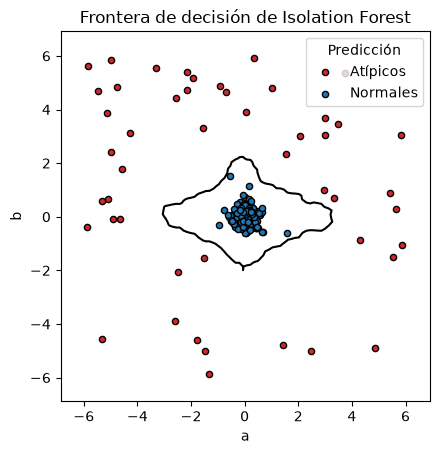

In [26]:
X = df[["a", "b"]]
etiquetas_if = IF.predict(X)

disp = DecisionBoundaryDisplay.from_estimator(
    IF,
    X,
    response_method="decision_function",
    plot_method="contour",
    levels=[0],
    colors="black",
)

ax = disp.ax_
for etiqueta, nombre, color in [
    (-1, "Atípicos", "tab:red"),
    (1, "Normales", "tab:blue"),
]:
    puntos = X.loc[etiquetas_if == etiqueta]
    ax.scatter(
        puntos["a"], puntos["b"],
        color=color, s=20, edgecolors="black", label=nombre,
    )

ax.set_title("Frontera de decisión de Isolation Forest")
ax.axis("square")
ax.legend(title="Predicción")
plt.show()


**Explicación línea por línea**

- `X = df[["a", "b"]]`: selecciona las columnas `a` y `b`.
- `etiquetas_if = IF.predict(X)`: usa el Isolation Forest ya entrenado para etiquetar cada punto (`1` normal, `-1` atípico).
- `disp = DecisionBoundaryDisplay.from_estimator(...)`: calcula y dibuja la frontera del modelo:
  - `IF, X`: el modelo y los datos.
  - `response_method="decision_function"`: usa el puntaje de anomalía de cada punto.
  - `plot_method="contour"`: dibuja líneas de contorno.
  - `levels=[0]`: solo traza el contorno donde el puntaje es 0, que es el límite entre normal y atípico.
  - `colors="black"`: la línea es negra.
- `ax = disp.ax_`: obtiene los ejes de la figura para seguir dibujando sobre ellos.
- `for etiqueta, nombre, color in [...]:`: recorre dos grupos, atípicos (`-1`, rojo) y normales (`1`, azul).
- `puntos = X.loc[etiquetas_if == etiqueta]`: filtra las filas del grupo actual.
- `ax.scatter(...)`: dibuja los puntos del grupo (`puntos["a"]` en el eje X y `puntos["b"]` en el eje Y), con tamaño `s=20`, borde negro (`edgecolors`) y la leyenda `label=nombre`.
- `ax.set_title("Frontera de decisión de Isolation Forest")`: pone el título del gráfico.
- `ax.axis("square")`: hace que ambos ejes tengan la misma escala.
- `ax.legend(title="Predicción")`: muestra la leyenda con el título "Predicción".
- `plt.show()`: muestra la figura.

In [27]:
# Eliminamos los outliers.
new_df = df[df_outliers==1]
print(new_df)


            a         b  outlier
0    0.149014 -0.041479        1
1    0.194307  0.456909        1
2   -0.070246 -0.070241        1
3    0.473764  0.230230        1
4   -0.140842  0.162768        1
..        ...       ...      ...
177 -4.981947  5.839675       -1
190 -2.571455  4.423190       -1
191 -3.316850  5.558670       -1
192 -5.854146  5.638546       -1
193 -5.482081  4.693717       -1

[150 rows x 3 columns]


**Explicación línea por línea**

- `# Eliminamos los outliers.`: comentario.
- `new_df = df[df_outliers==1]`: máscara booleana que conserva solo las filas etiquetadas como normales (`1`); el resultado se guarda en `new_df`. Usa las etiquetas del último modelo ejecutado (Local Outlier Factor).
- `print(new_df)`: imprime el DataFrame sin outliers.

**0.1.3 3) Box plot**

limite inferior:  -1.0853060827395105
limite superior:  1.0119554520872196
Posición de outliers:  [150 153 154 157 159 160 162 165 168 169 171 172 174 175 177 178 181 184
 185 186 187 190 191 192 193 195 151 152 155 156 161 163 164 166 167 173
 176 179 180 182 188 189 196 197]
Número de outliers:  44


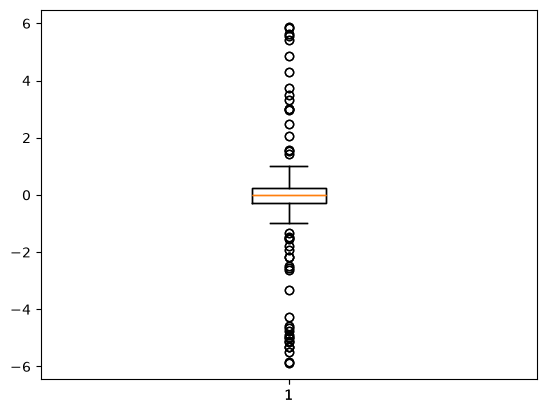

In [28]:
# Seleccionamos el atributo que vamos a medir.
a = df['a']
# Seleccionamos los umbrales a partir de los cuales consideramos outliers.
Q1 = stats.scoreatpercentile(a, 25)
Q3 = stats.scoreatpercentile(a, 75)
RIC = Q3 - Q1
li = Q1 - 1.5*RIC #xmin
ls = Q3 + 1.5*RIC #xmax
# Observamos los límites inferior y superior.
print('límite inferior: ', li)
print('límite superior: ', ls)
# Buscamos la posición de los outliers.
pos_i = np.where(a<li)[0]
pos_s = np.where(a>ls)[0]
pos_outliers = np.concatenate((pos_i, pos_s))
print('Posición de outliers: ', pos_outliers)
print('Número de outliers: ', len(pos_outliers))
# Dibujamos el diagrama de caja y bigotes.
prop = plt.boxplot(a)
plt.boxplot(a)
plt.show()


**Explicación línea por línea**

- `a = df['a']`: selecciona la columna `a`, que es la variable a analizar.
- `Q1 = stats.scoreatpercentile(a, 25)`: calcula el primer cuartil (percentil 25).
- `Q3 = stats.scoreatpercentile(a, 75)`: calcula el tercer cuartil (percentil 75).
- `RIC = Q3 - Q1`: rango intercuartílico, que mide la dispersión del 50 % central de los datos.
- `li = Q1 - 1.5*RIC`: límite inferior del diagrama de caja.
- `ls = Q3 + 1.5*RIC`: límite superior del diagrama de caja.
- `print('límite inferior: ', li)` y `print('límite superior: ', ls)`: imprimen ambos límites.
- `pos_i = np.where(a<li)[0]`: posiciones de los valores menores que el límite inferior.
- `pos_s = np.where(a>ls)[0]`: posiciones de los valores mayores que el límite superior.
- `pos_outliers = np.concatenate((pos_i, pos_s))`: une ambas listas de posiciones.
- `print('Posición de outliers: ', pos_outliers)` y `print('Número de outliers: ', len(pos_outliers))`: imprimen las posiciones y la cantidad.
- `prop = plt.boxplot(a)`: dibuja el diagrama de caja y bigotes y guarda sus elementos en `prop`.
- `plt.boxplot(a)`: lo dibuja de nuevo sobre el mismo gráfico (es redundante).
- `plt.show()`: muestra el gráfico.

In [32]:
# Definimos una función que, dada una columna de un dataframe, devuelva la
# posición de los outliers según el método box plot.
def find_limits_BP(variable):
    q1 = variable.quantile(0.25)
    q3 = variable.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    es_outlier = (variable < limite_inferior) | (variable > limite_superior)
    return np.flatnonzero(es_outlier.fillna(False).to_numpy())

pos_outliers = find_limits_BP(df["a"])
print("Posiciones:", pos_outliers)
print("Número de outliers:", len(pos_outliers))
print(df.iloc[pos_outliers])


Posiciones: [150 153 154 157 159 160 162 165 168 169 171 172 174 175 177 178 181 184
 185 186 187 190 191 192 193 195 151 152 155 156 161 163 164 166 167 173
 176 179 180 182 188 189 196 197]
Número de outliers: 44
            a         b  outlier
150 -2.615585 -3.870725       -1
153 -1.535783  3.316956       -1
154 -1.910358  5.169088       -1
157 -4.762514  4.830635       -1
159 -2.159405  4.746279       -1
160 -1.329580 -5.869948       -1
162 -2.168236  5.400744       -1
165 -2.481471 -2.056025       -1
168 -4.905527 -0.066956       -1
169 -5.309295  0.594347       -1
171 -1.789020 -4.595196       -1
172 -4.284100  3.138128       -1
174 -4.990718  2.411630       -1
175 -5.126844  3.862321       -1
177 -4.981947  5.839675       -1
178 -1.508750 -1.552294       -1
181 -1.484885 -4.997991       -1
184 -4.665630 -0.088499       -1
185 -5.863756 -0.376072       -1
186 -5.324361 -4.574185       -1
187 -4.589685  1.790524       -1
190 -2.571455  4.423190       -1
191 -3.316850  5.558670   

**Explicación línea por línea**

- Las dos primeras líneas con `#` son comentarios que describen la función.
- `def find_limits_BP(variable):`: define la función; recibe una columna (`Series`) de pandas.
- `q1 = variable.quantile(0.25)`: primer cuartil.
- `q3 = variable.quantile(0.75)`: tercer cuartil.
- `iqr = q3 - q1`: rango intercuartílico.
- `limite_inferior = q1 - 1.5 * iqr`: umbral inferior.
- `limite_superior = q3 + 1.5 * iqr`: umbral superior.
- `es_outlier = (variable < limite_inferior) | (variable > limite_superior)`: serie booleana que vale `True` donde el valor queda fuera de los límites.
- `return np.flatnonzero(es_outlier.fillna(False).to_numpy())`: reemplaza los valores nulos por `False`, convierte a arreglo de NumPy y devuelve las posiciones donde hay `True`.
- `pos_outliers = find_limits_BP(df["a"])`: llama a la función con la columna `a`. *Se corrigió la sangría: antes esta línea estaba dentro de la función, después del `return`, y nunca se ejecutaba.*
- `print("Posiciones:", pos_outliers)`: imprime las posiciones de los outliers.
- `print("Número de outliers:", len(pos_outliers))`: imprime la cantidad.
- `print(df.iloc[pos_outliers])`: muestra las filas completas de `df` que son outliers (`iloc` selecciona por posición).

In [33]:
pos_out = find_limits_BP(df["a"])

print("Posiciones de los outliers:", pos_out)
print("Número de outliers:", len(pos_out))

Posiciones de los outliers: [150 151 152 153 154 155 156 157 159 160 161 162 163 164 165 166 167 168
 169 171 172 173 174 175 176 177 178 179 180 181 182 184 185 186 187 188
 189 190 191 192 193 195 196 197]
Número de outliers: 44


**Explicación línea por línea**

- `pos_out = find_limits_BP(df["a"])`: aplica la función de box plot a la columna `a` y guarda las posiciones.
- `print("Posiciones de los outliers:", pos_out)`: imprime las posiciones.
- `print("Número de outliers:", len(pos_out))`: imprime cuántos outliers hay.

**0.1.4 4) Diccionario de palabras**

In [35]:
# Diccionario (glosario) con las palabras clave de este cuaderno.
glosario = {
    "outlier": "Dato atípico: valor que se aleja mucho del comportamiento general de los demás.",
    "inlier": "Dato normal, dentro del comportamiento esperado (etiqueta 1).",
    "DataFrame": "Tabla de filas y columnas de pandas.",
    "etiqueta": "Resultado de la predicción para cada fila: 1 (normal) o -1 (atípico).",
    "contamination": "Proporción esperada de outliers en los datos.",
    "random_state": "Semilla que hace reproducible un resultado aleatorio.",
    "fit": "Método que entrena el modelo con los datos.",
    "predict": "Método que etiqueta datos usando un modelo ya entrenado.",
    "fit_predict": "Entrena el modelo y devuelve las etiquetas en un solo paso.",
    "EllipticEnvelope": "Detector que ajusta una elipse (distribución gaussiana) a los datos normales.",
    "IsolationForest": "Detector que aísla los puntos con árboles aleatorios; los atípicos se aíslan más rápido.",
    "OneClassSVM": "Máquina de soporte vectorial que aprende la frontera de los datos normales.",
    "LocalOutlierFactor": "Detector que compara la densidad local de un punto con la de sus vecinos.",
    "kernel": "Función que transforma los datos para separarlos en el SVM (por ejemplo, rbf).",
    "gamma": "Parámetro que controla el alcance del kernel rbf.",
    "nu": "Cota superior de la fracción de outliers en One-Class SVM.",
    "n_neighbors": "Número de vecinos que usa Local Outlier Factor.",
    "frontera de decisión": "Línea que separa los puntos normales de los atípicos.",
    "box plot": "Diagrama de caja y bigotes que resume la distribución y marca los atípicos.",
    "cuartil": "Valor que divide los datos ordenados en cuatro partes iguales (Q1, Q2, Q3).",
    "RIC": "Rango intercuartílico: Q3 - Q1 (en inglés, IQR).",
    "límite inferior": "Q1 - 1.5 * RIC; los valores menores son outliers.",
    "límite superior": "Q3 + 1.5 * RIC; los valores mayores son outliers.",
    "np.where": "Función de NumPy que devuelve las posiciones donde se cumple una condición.",
    "scoreatpercentile": "Función de SciPy que calcula el valor de un percentil.",
}

# Mostramos el glosario ordenado alfabéticamente.
for palabra, definicion in sorted(glosario.items()):
    print(f"{palabra}: {definicion}")


DataFrame: Tabla de filas y columnas de pandas.
EllipticEnvelope: Detector que ajusta una elipse (distribución gaussiana) a los datos normales.
IsolationForest: Detector que aísla los puntos con árboles aleatorios; los atípicos se aíslan más rápido.
LocalOutlierFactor: Detector que compara la densidad local de un punto con la de sus vecinos.
OneClassSVM: Máquina de soporte vectorial que aprende la frontera de los datos normales.
RIC: Rango intercuartílico: Q3 - Q1 (en inglés, IQR).
box plot: Diagrama de caja y bigotes que resume la distribución y marca los atípicos.
contamination: Proporción esperada de outliers en los datos.
cuartil: Valor que divide los datos ordenados en cuatro partes iguales (Q1, Q2, Q3).
etiqueta: Resultado de la predicción para cada fila: 1 (normal) o -1 (atípico).
fit: Método que entrena el modelo con los datos.
fit_predict: Entrena el modelo y devuelve las etiquetas en un solo paso.
frontera de decisión: Línea que separa los puntos normales de los atípicos.
gam

**Explicación línea por línea**

- `glosario = {...}`: crea un diccionario de Python; cada *clave* es una palabra del cuaderno y su *valor* es la definición.
- `for palabra, definicion in sorted(glosario.items()):`: `items()` entrega los pares (clave, valor), `sorted` los ordena alfabéticamente y el `for` los recorre uno por uno.
- `print(f"{palabra}: {definicion}")`: imprime cada palabra seguida de su definición usando una f-string.